# EMQA_L5_fwd_curve

**The Romanian baseload forward curve**

Energy Markets Quantitative Analysis (EMQA), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L5/EMQA_L5_fwd_curve/EMQA_L5_fwd_curve.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

The forward curve today: products traded in the last three months for delivery after the cut-off.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
# fixed colour per entity (course palette)
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def show(label, value, key=None, fmt='.2f'):
    """Print one number of the slide; [key] = its name in lectures/L5/L5_numbers.json."""
    s = value if isinstance(value, str) else format(value, fmt)
    print(f'{label:<58s} {s:>12s}' + (f'   [{key}]' if key else ''))

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month of the Romanian series
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
d = lambda ts: pd.Timestamp(ts).strftime('%Y-%m-%d')
print('cut-off (last complete month):', d(END))

cut-off (last complete month): 2026-10-31


In [4]:
# OPCOM PCCB-LE-flex auction results: one row per traded session, price converted to EUR with the ECB EUR/RON fixing
FW = pd.read_csv(DATA + 'opcom_forward_trades.csv', parse_dates=['auction_date', 'delivery_start', 'delivery_end'])
FW = FW[FW['auction_date'] <= END].copy()


def kind_of(s, e):
    """Standard delivery period of a product: M (month), Q (quarter), H (half-year), Y (calendar year), else 'other'."""
    if s.day != 1 or (e + pd.Timedelta(days=1)).day != 1:
        return 'other'
    n = (e.year - s.year) * 12 + e.month - s.month + 1
    if n == 1:
        return 'M'
    if n == 3 and s.month in (1, 4, 7, 10):
        return 'Q'
    if n == 6 and s.month in (1, 7):
        return 'H'
    if n == 12 and s.month == 1:
        return 'Y'
    return 'other'


FW['kind'] = [kind_of(s, e) for s, e in zip(FW['delivery_start'], FW['delivery_end'])]
FW['lead_m'] = ((FW['delivery_start'].dt.year - FW['auction_date'].dt.year) * 12 +
                FW['delivery_start'].dt.month - FW['auction_date'].dt.month)
# baseload ('banda LD') products with a standard delivery period
BASE = FW[(FW['profile'] == 'banda LD') & (FW['kind'] != 'other')].copy()


def vwap(df):
    """Volume-weighted average price, EUR/MWh."""
    return float(np.average(df['price_eur_mwh'], weights=df['mwh'])) if len(df) else np.nan


def realised(s, e, col='RO'):
    """Mean day-ahead base price over [s, e] (CET days); NaN unless every day is present."""
    x = PD.loc[s:e, col]
    full = len(x) == (e - s).days + 1 and x.notna().all()
    return float(x.mean()) if full else np.nan


print(len(FW), 'traded auctions from', d(FW['auction_date'].min()), 'to', d(FW['auction_date'].max()),
      '|', len(BASE), 'baseload auctions with a standard delivery period')

2298 traded auctions from 2020-05-12 to 2026-10-28 | 1361 baseload auctions with a standard delivery period


In [5]:
# forward curve: baseload products traded in the last three months for delivery after the cut-off, VWAP per product
CURVE_FROM = (END - pd.DateOffset(months=2) + pd.Timedelta(days=1)).normalize()
cur = BASE[(BASE['auction_date'] >= CURVE_FROM) & (BASE['delivery_start'] > END)]
curve = (cur.groupby(['delivery_start', 'delivery_end', 'kind'])
         .apply(lambda g: pd.Series({'F': vwap(g), 'n': len(g), 'twh': g['mwh'].sum() / 1e6})).reset_index())
print(curve.round(2).to_string())
show('products on the curve', len(curve), 'curve.n_products', 'd')
show('auctions on the curve', len(cur), 'curve.n_sessions', 'd')
cal = curve[curve['kind'] == 'Y'].sort_values('delivery_start')
show(f"next calendar year ({cal['delivery_start'].iloc[0].year}), EUR/MWh", cal['F'].iloc[0], 'curve.cal_next.F', '.1f')
mth = curve[curve['kind'] == 'M'].sort_values('delivery_start')
if len(mth):
    show(f"front month ({mth['delivery_start'].iloc[0]:%Y-%m}), EUR/MWh", mth['F'].iloc[0], 'curve.m_front.F', '.1f')
qq = curve[curve['kind'] == 'Q'].sort_values('delivery_start')
if len(qq):
    show(f"front quarter (from {d(qq['delivery_start'].iloc[0])}), EUR/MWh", qq['F'].iloc[0], 'curve.q_front.F', '.1f')
show('mean spot of the last three months, EUR/MWh', PD.loc[END - pd.DateOffset(months=3) + pd.Timedelta(days=1):END, 'RO'].mean(),
     'curve.spot_last3', '.1f')
show('mean spot of the last month, EUR/MWh', PD.loc[END.replace(day=1):END, 'RO'].mean(), 'curve.spot_lastm', '.1f')

  delivery_start delivery_end kind       F     n   twh
0     2026-11-01   2026-11-30    M  215.33   4.0  0.01
1     2026-12-01   2026-12-31    M  214.27   3.0  0.01
2     2027-01-01   2027-01-31    M  203.04   7.0  0.03
3     2027-01-01   2027-03-31    Q  176.69  13.0  0.18
4     2027-01-01   2027-12-31    Y  148.12  50.0  2.47
5     2027-02-01   2027-02-28    M  201.14   7.0  0.02
6     2027-03-01   2027-03-31    M  159.65   1.0  0.00
products on the curve                                                 7   [curve.n_products]
auctions on the curve                                                85   [curve.n_sessions]
next calendar year (2027), EUR/MWh                                148.1   [curve.cal_next.F]
front month (2026-11), EUR/MWh                                    215.3   [curve.m_front.F]
front quarter (from 2027-01-01), EUR/MWh                          176.7   [curve.q_front.F]
mean spot of the last three months, EUR/MWh                       189.0   [curve.spot_last3]
mean

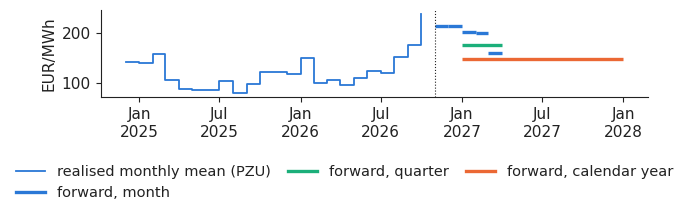

In [6]:
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
MON = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
KCOL = {'M': PAL['RO'], 'Q': PAL['HU'], 'H': PAL['BG'], 'Y': PAL['DE_LU']}
KL = {'M': 'month', 'Q': 'quarter', 'H': 'half-year', 'Y': 'calendar year'}
SPOT_M = PD['RO'].loc[:END].resample('MS').mean()
fig, ax = plt.subplots(figsize=(6.4, 2.2))
sp = SPOT_M.loc[END - pd.DateOffset(months=23):]
ax.step(sp.index, sp.values, where='post', color=PAL['RO'], lw=1.3)
for r in curve.sort_values('kind').itertuples():
    ax.hlines(r.F, r.delivery_start, r.delivery_end + pd.Timedelta(days=1), color=KCOL[r.kind], lw=2.4)
ks = [k for k in ['M', 'Q', 'H', 'Y'] if (curve['kind'] == k).any()]
hnd = [Line2D([], [], color=PAL['RO'], lw=1.3)] + [Line2D([], [], color=KCOL[k], lw=2.4) for k in ks]
lab = ['realised monthly mean (PZU)'] + ['forward, ' + KL[k] for k in ks]
ax.axvline(END + pd.Timedelta(days=1), color='#222222', lw=0.8, ls=':')     # cut-off
ax.set_ylabel('EUR/MWh')
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: MON[mdates.num2date(v).month - 1] + f'\n{mdates.num2date(v).year}'))
legend_bottom(fig, handles=hnd, labels=lab, ncol=3)
fig.tight_layout(rect=(0, 0.26, 1, 1))
plt.savefig('fwd_curve.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()